# 01 — Data Audit & Exploratory Data Analysis (EDA)
**Dự án:** Medical Chatbot — Phân loại bệnh dựa trên triệu chứng (ML Core)

Notebook này phục vụ nghiên cứu khám phá, khảo sát dữ liệu thô và trực quan hóa phân phối:
1. Khảo sát cấu trúc dataset (`Disease and symptoms dataset.csv`).
2. Kiểm tra tính toàn vẹn (Missing values, Data types, Range).
3. Phân tích phân phối cột nhãn `diseases` (Imbalance, Long-tail distribution).
4. Phân tích độ thưa của triệu chứng và phát hiện 49 cột triệu chứng có tổng bằng 0.
5. Phát hiện các bản ghi trùng lặp hoàn toàn (Exact Duplicates) và xung đột nhãn (Label Conflicts).
6. Trực quan hóa các phân phối chính.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình hiển thị
pd.set_option('display.max_columns', 50)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

DATA_PATH = os.path.join('..', 'data/raw/Disease and symptoms dataset.csv')
if not os.path.exists(DATA_PATH):
    DATA_PATH = '../data/raw/Disease and symptoms dataset.csv'

print(f'Đường dẫn file dữ liệu: {DATA_PATH}')

Đường dẫn file dữ liệu: ..\data/raw/Disease and symptoms dataset.csv


## 1. Tải và kiểm tra tổng quan cấu trúc dữ liệu

In [6]:
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f'Số dòng (Records): {len(df):,}')
print(f'Số cột (Columns): {len(df.columns):,}')
print(f'Số ô missing (null): {df.isnull().sum().sum()}')
df.head(5)
df.tail(5)

Số dòng (Records): 246,945
Số cột (Columns): 378
Số ô missing (null): 0


,diseases,anxiety and nervousness,depression,shortness of breath,depressive or psychotic symptoms,sharp chest pain,dizziness,insomnia,abnormal involuntary movements,chest tightness,palpitations,irregular heartbeat,breathing fast,hoarse voice,sore throat,difficulty speaking,cough,nasal congestion,throat swelling,diminished hearing,lump in throat,throat feels tight,difficulty in swallowing,skin swelling,retention of urine,...,elbow lump or mass,muscle weakness,throat redness,joint swelling,tongue pain,redness in or around nose,wrinkles on skin,foot or toe weakness,hand or finger cramps or spasms,back stiffness or tightness,wrist lump or mass,skin pain,low back stiffness or tightness,low urine output,skin on head or neck looks infected,stuttering or stammering,problems with orgasm,nose deformity,lump over jaw,sore in nose,hip weakness,back swelling,ankle stiffness or tightness,ankle weakness,neck weakness
246940,open wound of the nose,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
246941,open wound of the nose,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
246942,open wound of the nose,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
246943,open wound of the nose,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
246944,open wound of the nose,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 2. Phân tích cột mục tiêu (Target: `diseases`)

Tổng số bệnh duy nhất: 773
Bệnh có nhiều mẫu nhất: cystitis (1219 mẫu)
Bệnh có ít mẫu nhất: kaposi sarcoma (1 mẫu)
Số bệnh có đúng 1 mẫu duy nhất: 19
Số bệnh có <= 5 mẫu: 61
Số bệnh có < 10 mẫu: 96
Số mẫu trung bình trên 1 bệnh: 319.46


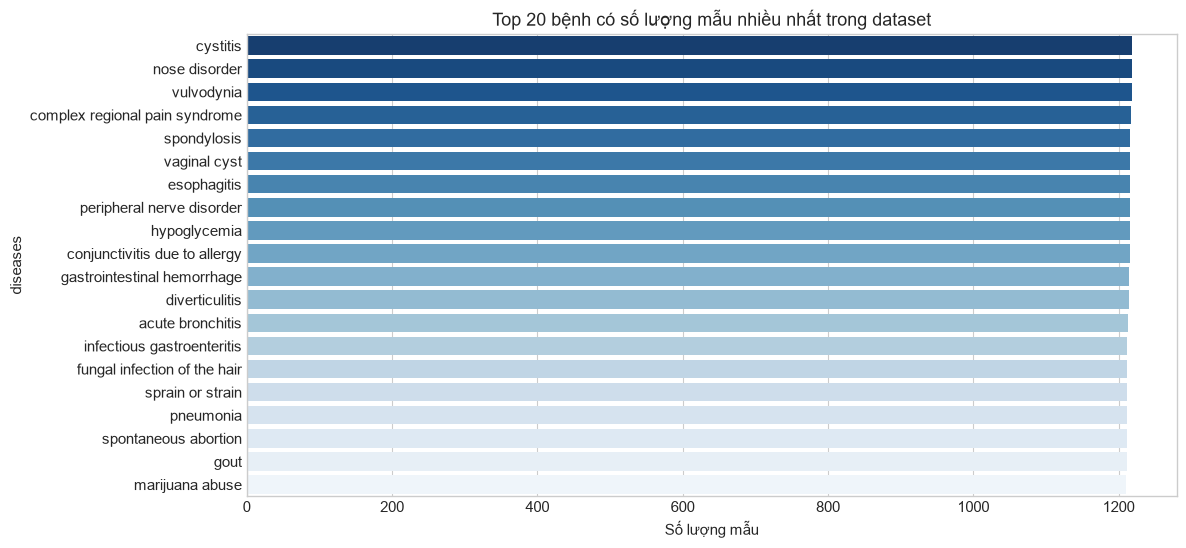

In [7]:
disease_counts = df['diseases'].value_counts()
print(f'Tổng số bệnh duy nhất: {len(disease_counts)}')
print(f'Bệnh có nhiều mẫu nhất: {disease_counts.index[0]} ({disease_counts.iloc[0]} mẫu)')
print(f'Bệnh có ít mẫu nhất: {disease_counts.index[-1]} ({disease_counts.iloc[-1]} mẫu)')
print(f'Số bệnh có đúng 1 mẫu duy nhất: {(disease_counts == 1).sum()}')
print(f'Số bệnh có <= 5 mẫu: {(disease_counts <= 5).sum()}')
print(f'Số bệnh có < 10 mẫu: {(disease_counts < 10).sum()}')
print(f'Số mẫu trung bình trên 1 bệnh: {disease_counts.mean():.2f}')
# Trực quan hóa Top 20 bệnh phổ biến nhất
plt.figure(figsize=(12, 6))
sns.barplot(x=disease_counts.head(20).values, y=disease_counts.head(20).index, hue=disease_counts.head(20).index, palette='Blues_r', legend=False)
plt.title('Top 20 bệnh có số lượng mẫu nhiều nhất trong dataset')
plt.xlabel('Số lượng mẫu')
plt.show()

## 3. Phân tích đặc trưng triệu chứng và độ thưa (Sparsity)

Thống kê số lượng triệu chứng mỗi bệnh nhân:
count    246945.000000
mean          5.332851
std           1.640610
min           1.000000
25%           4.000000
50%           5.000000
75%           6.000000
max          12.000000
dtype: float64

Số cột triệu chứng không bao giờ xuất hiện (sum == 0): 49


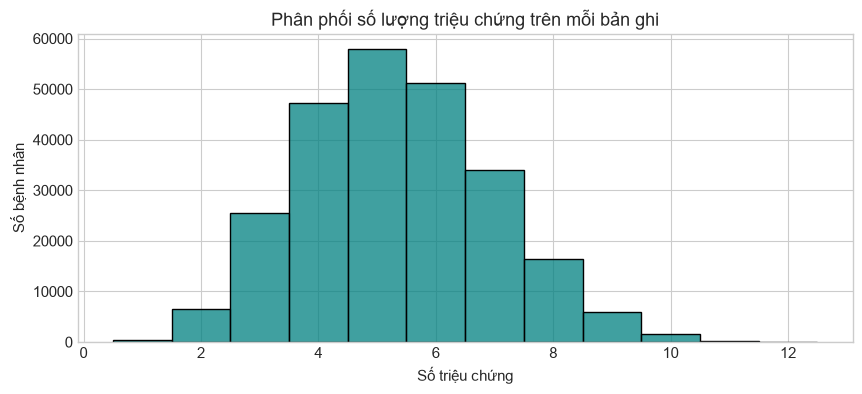

In [4]:
feature_cols = [c for c in df.columns if c != 'diseases']
features_df = df[feature_cols]

# Thống kê số triệu chứng trên từng mẫu
symptom_counts_per_sample = features_df.sum(axis=1)
print('Thống kê số lượng triệu chứng mỗi bệnh nhân:')
print(symptom_counts_per_sample.describe())

# Kiểm tra 49 cột triệu chứng có tổng bằng 0
col_sums = features_df.sum(axis=0)
zero_sum_cols = col_sums[col_sums == 0].index.tolist()
print(f'\nSố cột triệu chứng không bao giờ xuất hiện (sum == 0): {len(zero_sum_cols)}')

plt.figure(figsize=(10, 4))
sns.histplot(symptom_counts_per_sample, bins=12, discrete=True, color='teal')
plt.title('Phân phối số lượng triệu chứng trên mỗi bản ghi')
plt.xlabel('Số triệu chứng')
plt.ylabel('Số bệnh nhân')
plt.show()

## 4. Phát hiện trùng lặp hoàn toàn (Exact Duplicates) & Xung đột nhãn (Label Conflicts)

In [5]:
# 1. Trùng lặp hoàn toàn
exact_dups = int(df.duplicated().sum())
print(f'Số dòng trùng lặp 100% (cả symptoms và disease): {exact_dups:,} ({exact_dups/len(df)*100:.2f}%)')

# 2. Xung đột nhãn (Cùng tập triệu chứng nhưng khác bệnh)
grouped = df.groupby(feature_cols)['diseases'].nunique()
conflicts = int((grouped > 1).sum())
print(f'Số vector triệu chứng bị gán cho >= 2 bệnh: {conflicts:,}')

Số dòng trùng lặp 100% (cả symptoms và disease): 57,298 (23.20%)
Số vector triệu chứng bị gán cho >= 2 bệnh: 12,634


In [8]:
duplicates = df[df.duplicated(keep=False)]

print(f"Số dòng thuộc nhóm trùng lặp: {len(duplicates)}")
display(duplicates)

Số dòng thuộc nhóm trùng lặp: 94067


,diseases,anxiety and nervousness,depression,shortness of breath,depressive or psychotic symptoms,sharp chest pain,dizziness,insomnia,abnormal involuntary movements,chest tightness,palpitations,irregular heartbeat,breathing fast,hoarse voice,sore throat,difficulty speaking,cough,nasal congestion,throat swelling,diminished hearing,lump in throat,throat feels tight,difficulty in swallowing,skin swelling,retention of urine,...,elbow lump or mass,muscle weakness,throat redness,joint swelling,tongue pain,redness in or around nose,wrinkles on skin,foot or toe weakness,hand or finger cramps or spasms,back stiffness or tightness,wrist lump or mass,skin pain,low back stiffness or tightness,low urine output,skin on head or neck looks infected,stuttering or stammering,problems with orgasm,nose deformity,lump over jaw,sore in nose,hip weakness,back swelling,ankle stiffness or tightness,ankle weakness,neck weakness
7,panic disorder,0,0,0,1,0,0,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,panic disorder,1,0,0,1,0,1,1,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
11,panic disorder,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
13,panic disorder,1,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
20,panic disorder,0,0,1,1,0,0,1,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
246934,open wound of the nose,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
246939,open wound of the nose,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
246940,open wound of the nose,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
246941,open wound of the nose,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
